# Understanding the fungal growth dataset

This dataset summarizes experiments in which yeasts were grown in different liquid growth media. It brings together two kinds of information: **how much and how quickly each organism grew**, and **what was recorded about the medium it grew in**. These are experimental growth summaries, rather than predictions from the metabolic models.

The file covers **12 organism/strain labels, each tested in the same 29 media**, giving 348 rows. For example, one row describes *Hanseniaspora uvarum* C04561 in a particular wheat-straw medium. Another row describes a different organism in that same medium. Some labels refer to different strains of the same species, so 12 labels do not mean 12 distinct species.

The media include wheat- and oat-straw or bran conditions, corn-stover conditions, and media labelled YPD or YNB. Some labels distinguish pretreatment settings or dilution variants. The 25 chemical columns record substances such as glucose, xylose, acetate, and furfural. These values describe the medium and repeat across organisms tested in it; they do not measure how much an organism consumed. The listed chemicals are only part of the medium description, not a complete recipe.

For each organism–medium combination, the growth columns summarize different aspects of the response. Maximum growth rate describes how quickly growth occurred; biomass describes the reported amount of growth; area under the growth curve combines the magnitude and duration of the growth signal. The CSV provides these summaries without the underlying time-series curves, replicate identifiers, or uncertainty estimates.

Read the three plots in order: **maximum growth rate**, **biomass**, then **medium composition**. Growth rate describes how quickly growth occurs; biomass describes the reported amount of growth. These are complementary measurements.

| Source columns | What they summarize |
| --- | --- |
| `growth_max`, `growth_max_sandra` | Maximum growth rate |
| `Biomass`, `Net_Biomass` | Biomass and net biomass |
| `AUC`, `AUC_sandra`, `NetAUC_sandra` | Area under the growth curve |
| `Relative_control` | Response relative to a control |

Units, the meaning of “net”, and differences between original and `_sandra` processing need confirmation. `Biomass` is not established as dry mass or a model biomass flux.

Source: [Growth_data_for_ML_Helsinki_Uni.csv](metabolic_models/Growth_data_for_ML_Helsinki_Uni.csv). Run from the repository root. For metabolic-model simulations, see [fungi_exploration.ipynb](fungi_exploration.ipynb).

In [1]:
%matplotlib inline
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import HTML, display

csv_path = Path("metabolic_models/Growth_data_for_ML_Helsinki_Uni.csv")
data = pd.read_csv(csv_path)
response_columns = ["AUC", "NetAUC_sandra", "AUC_sandra", "growth_max",
                    "growth_max_sandra", "Biomass", "Net_Biomass", "Relative_control"]
process_columns = ["Temperature", "Time", "Dilution"]
chemical_columns = [col for col in data if col not in
                    ["organism_id", "medium_id", *response_columns, *process_columns]]
organisms = data["organism_id"].drop_duplicates().tolist()
media_order = data["medium_id"].drop_duplicates().tolist()
assert not data.duplicated(["organism_id", "medium_id"]).any()
assert len(data) == len(organisms) * len(media_order)
assert data.groupby("medium_id")[[*process_columns, *chemical_columns]].nunique().le(1).all().all()
raw_data = data.copy(deep=True)
for column in response_columns:
    data[column] = pd.to_numeric(data[column], errors="coerce")
original_fit_failed = raw_data["growth_max"].eq("cannot fit data")

plt.rcParams.update({"font.size": 10, "figure.dpi": 110})
def show_table(frame):
    display(HTML('<div style="max-height:420px;overflow:auto">' +
                 frame.to_html(index=False, escape=True, border=0) + '</div>'))

show_table(pd.DataFrame({
    "What": ["Organism/strain labels", "Media", "Organism × medium rows",
             "Growth-summary columns", "Recorded chemical columns", "Original growth fits that failed"],
    "Count": [len(organisms), len(media_order), len(data), len(response_columns),
              len(chemical_columns), int(original_fit_failed.sum())],
}))

What,Count
Organism/strain labels,12
Media,29
Organism × medium rows,348
Growth-summary columns,8
Recorded chemical columns,25
Original growth fits that failed,18


## 1. Maximum growth rate: how quickly did growth occur?

Colour shows **`growth_max_sandra`**: brighter cells have larger reported values, using one scale across all organisms and media. All 348 entries are numeric; the relationship to the original `growth_max` needs confirmation.

**× marks an original `growth_max` fit labelled “cannot fit data”** (18 rows). The Sandra value is displayed, but its reliability is unresolved. A recorded zero is not independently confirmed absence of growth; grey would indicate a missing numeric value.

Read across a row to compare media for one organism, or down a column to compare organisms in one medium. Short medium labels preserve CSV order, and organism labels retain strain identifiers. Units are unspecified.

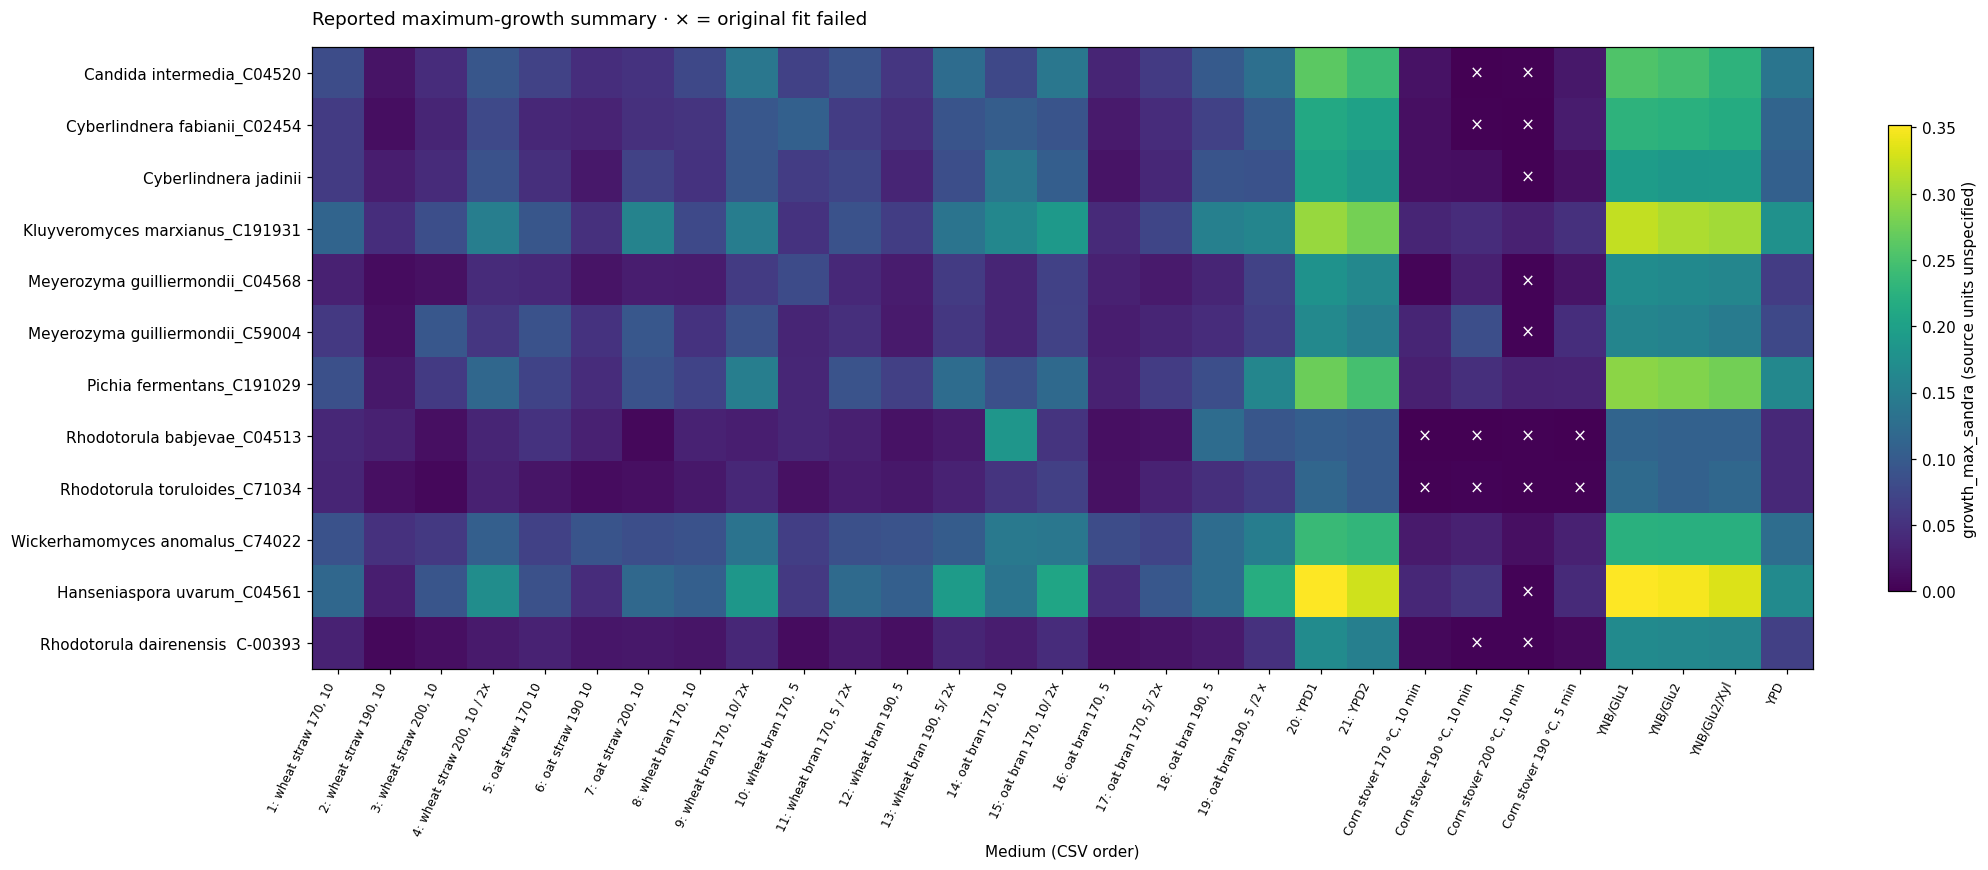

In [2]:
def medium_label(name):
    if name.startswith("Medium "):
        number = name.split()[1].split("(")[0]
        description = name.split("(", 1)[1].rstrip(")")
        return f"{number}: {description}"
    return name.replace("Corn stover (FIN), ", "Corn stover ")

medium_labels = [medium_label(name) for name in media_order]

def matrix_for(metric):
    return data.pivot(index="organism_id", columns="medium_id", values=metric).reindex(
        index=organisms, columns=media_order)

failed_matrix = (raw_data.assign(failed=original_fit_failed)
                 .pivot(index="organism_id", columns="medium_id", values="failed")
                 .reindex(index=organisms, columns=media_order).to_numpy())

def growth_heatmap(metric, title):
    matrix = matrix_for(metric)
    fig, ax = plt.subplots(figsize=(18, 7.8), layout="constrained")
    cmap = plt.get_cmap("viridis").copy()
    cmap.set_bad("#cccccc")
    im = ax.imshow(matrix.to_numpy(), aspect="auto", cmap=cmap, vmin=0)
    ax.set_xticks(range(len(media_order)), medium_labels, rotation=65, ha="right", fontsize=8)
    ax.set_yticks(range(len(organisms)), organisms)
    ax.set_xlabel("Medium (CSV order)")
    ax.set_title(title, loc="left", pad=15)
    if metric in ["growth_max", "growth_max_sandra"]:
        for row, col in zip(*np.where(failed_matrix)):
            ax.text(col, row, "×", ha="center", va="center", color="white", fontsize=11)
    fig.colorbar(im, ax=ax, shrink=0.75, label=metric + " (source units unspecified)")
    plt.show()

growth_heatmap("growth_max_sandra", "Reported maximum-growth summary · × = original fit failed")

## 2. Biomass: how much growth was reported?

Colour shows **`Biomass`**, with the same organism and medium order as the growth-rate plot. Its colour scale is independent because biomass and growth rate are different quantities. A larger biomass value does not necessarily mean faster growth.

This is the source `Biomass` column, without additional normalization or subtraction. Its assay, measurement time, and units are unspecified; do not assume dry mass. The × markers above refer to original growth-rate fit failures, not biomass-quality flags.

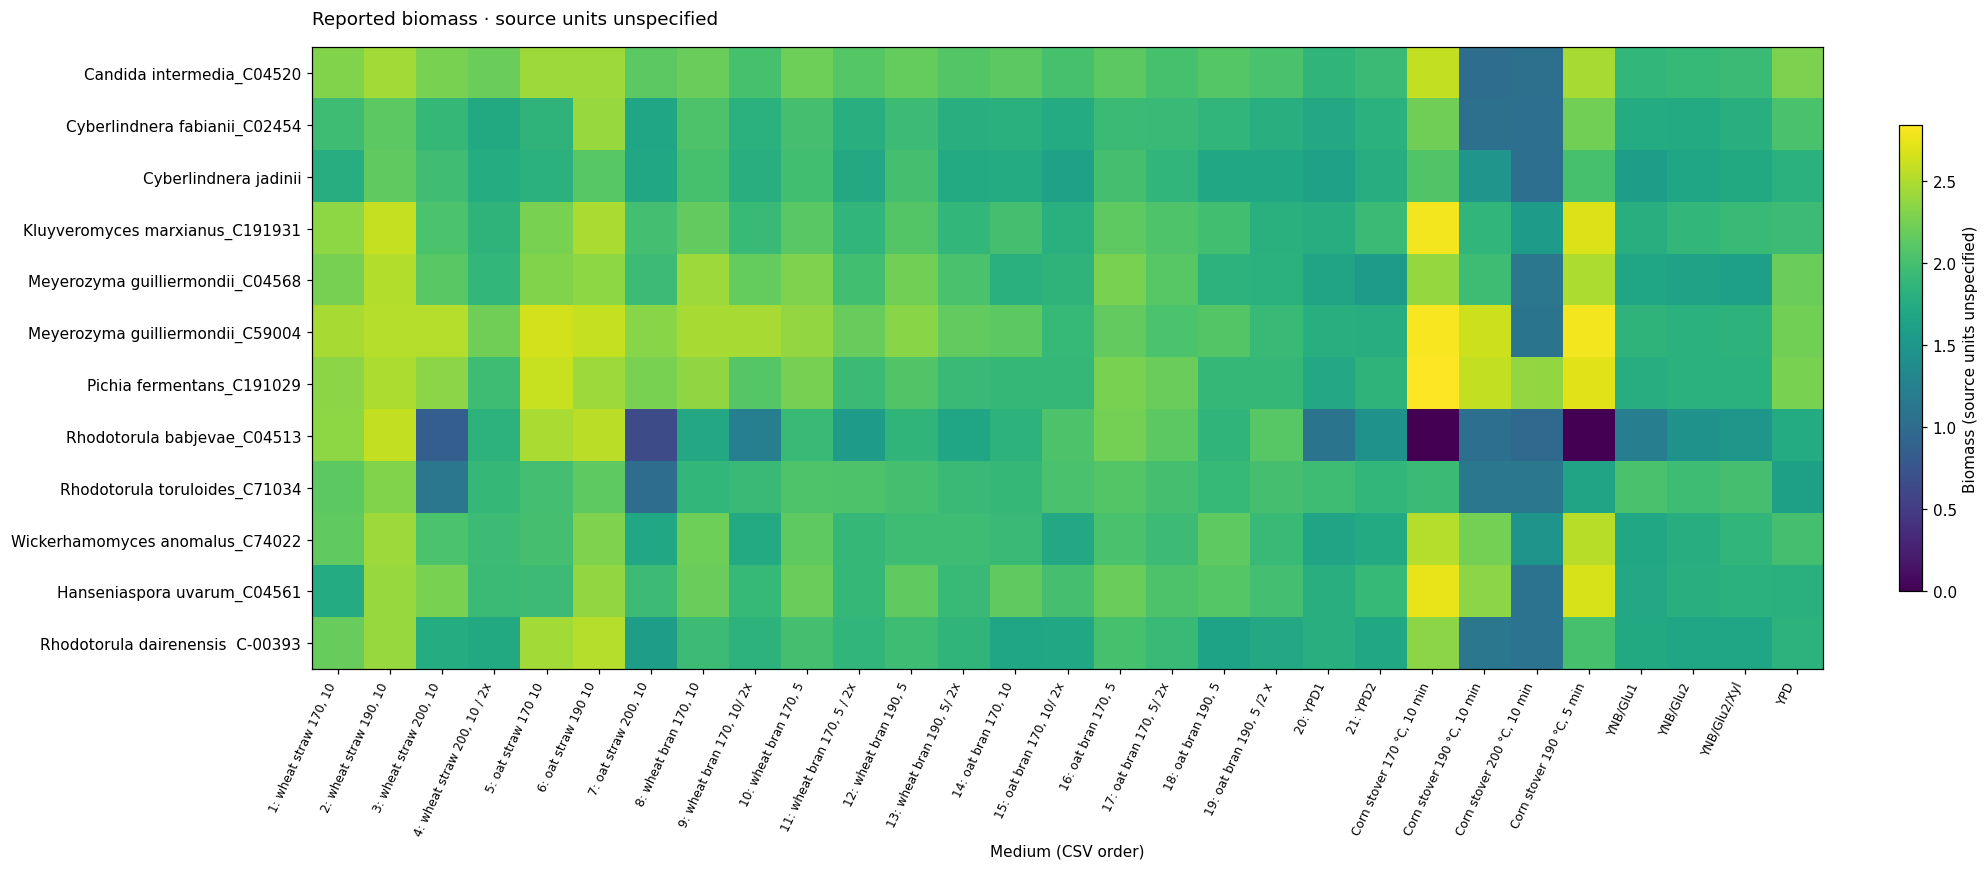

In [3]:
growth_heatmap("Biomass", "Reported biomass · source units unspecified")

## 3. Medium composition: what differs between conditions?

Each row below is **one medium**, with 25 recorded chemical fields. Each chemical has its **own minimum–maximum scale across media**: 0 = its lowest recorded value, 1 = its highest. Constant columns are grey. Colours reveal within-chemical patterns, not absolute differences between chemicals.

Chemical units are absent and may differ between columns. Original spellings are preserved (`manose` means mannose). The plotted values are not model uptake bounds, and these fields are not a complete recipe: an unlisted nutrient is not necessarily absent.

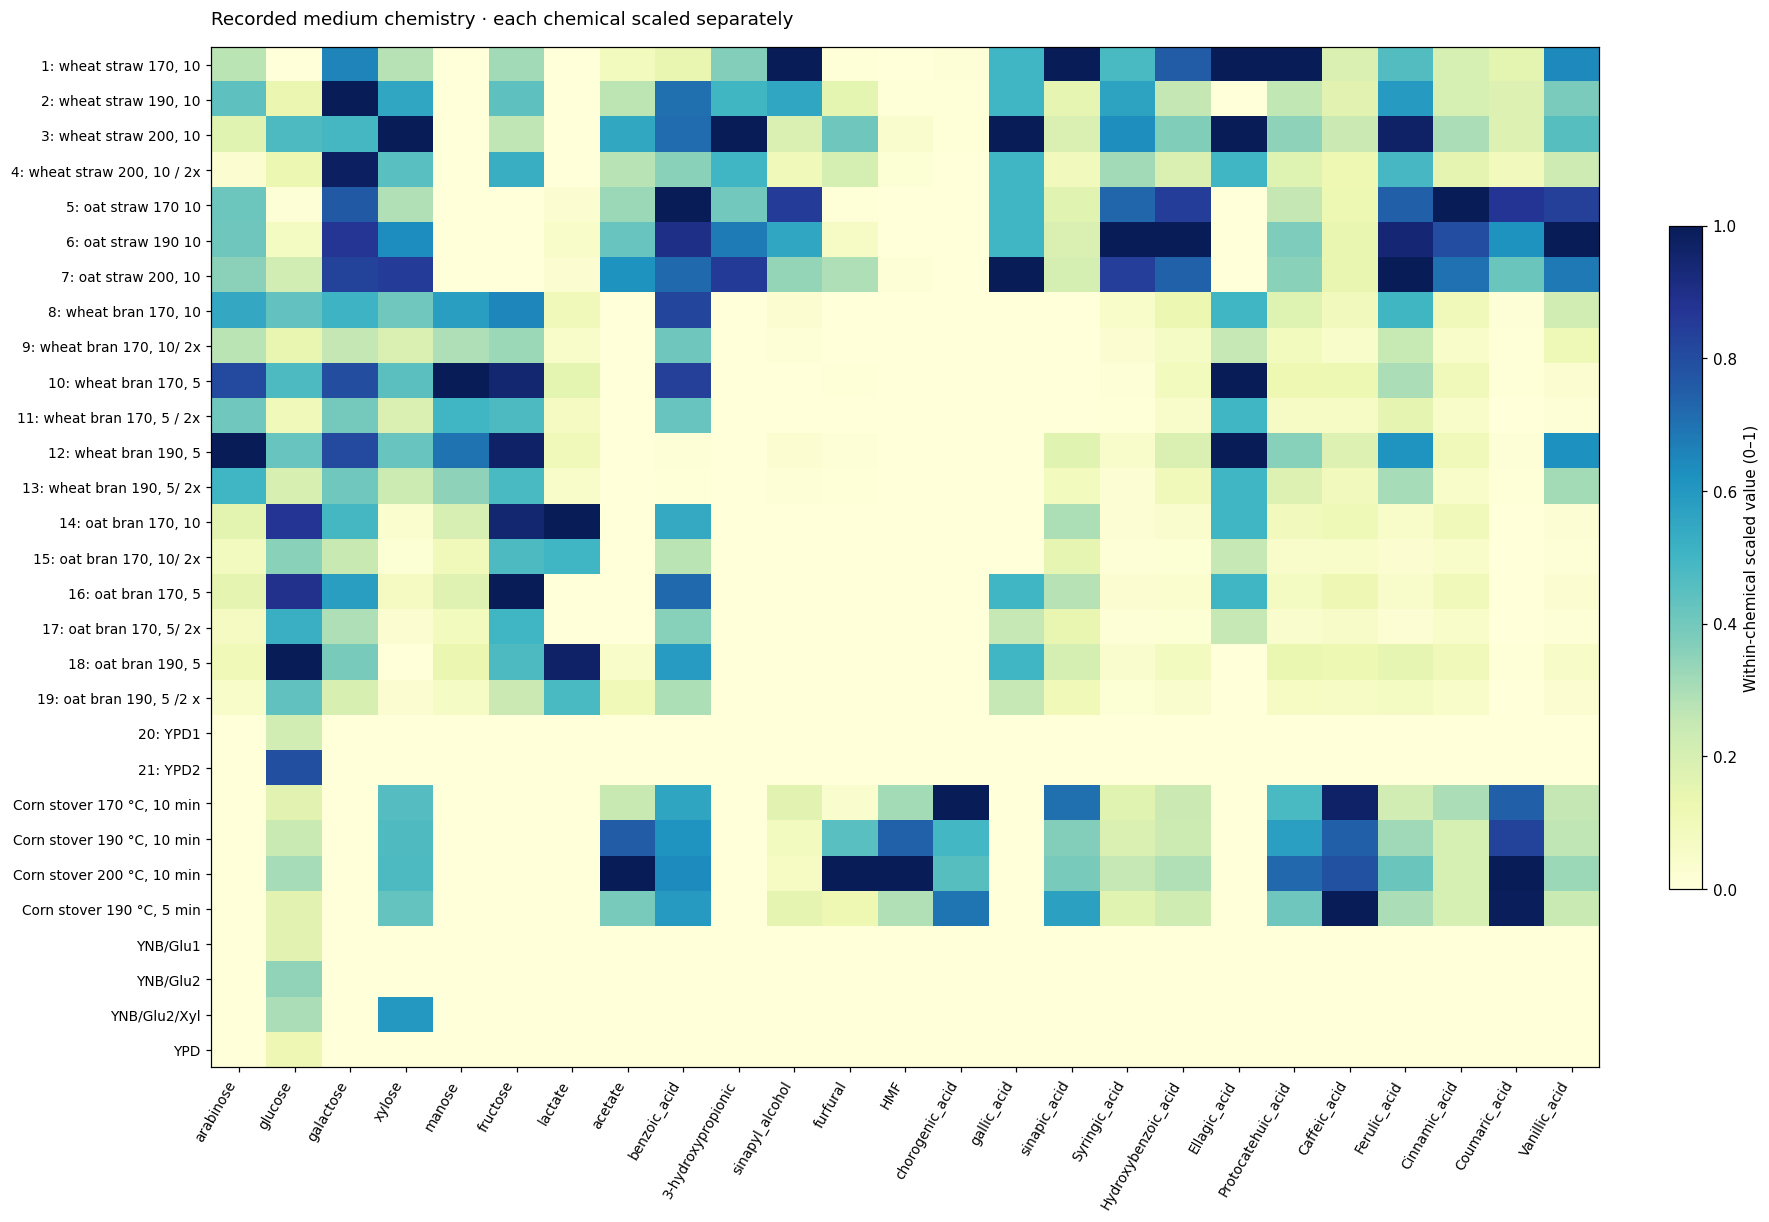

In [4]:
medium_data = data.drop_duplicates("medium_id").set_index("medium_id").reindex(media_order)
chemistry = medium_data[chemical_columns]
chemical_ranges = chemistry.max() - chemistry.min()
scaled_chemistry = (chemistry - chemistry.min()).div(chemical_ranges.replace(0, np.nan))
fig, ax = plt.subplots(figsize=(16, 11), layout="constrained")
cmap = plt.get_cmap("YlGnBu").copy()
cmap.set_bad("#cccccc")
im = ax.imshow(scaled_chemistry.to_numpy(), aspect="auto", cmap=cmap, vmin=0, vmax=1)
ax.set_xticks(range(len(chemical_columns)), chemical_columns, rotation=60, ha="right", fontsize=9)
ax.set_yticks(range(len(media_order)), medium_labels, fontsize=9)
ax.set_title("Recorded medium chemistry · each chemical scaled separately", loc="left", pad=15)
fig.colorbar(im, ax=ax, shrink=0.65, label="Within-chemical scaled value (0–1)")
plt.show()

## Essential limits when reading the plots

- **Missing fits:** `AUC` and `growth_max` each contain 18 “cannot fit data” entries, all in corn-stover conditions. They are treated as missing, not zero. Numeric Sandra values do not establish fit reliability.
- **Medium labels:** temperature/time appear to describe pretreatment, not cultivation. The label “Corn stover (FIN), 200 °C, 10 min” conflicts with the recorded `Time=5`. Source values are preserved; dilution profiles are not recomputed from labels.
- **Measurement limits:** no raw growth curves, replicate identifiers, or uncertainty estimates are supplied. These plots describe reported summaries and do not establish that a particular chemical causes a growth difference.

Detailed provenance and unresolved definitions are recorded in [the fungi working notes](docs/working_notes/fungi_experiment_notes.md).